In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("arac_fiyat_tahmini.csv")

In [4]:
df.head()

,marka,model_yili,kilometre,motor_hacmi_cc,yakit_turu,vites,beygir_gucu,hasar_kaydi_adedi,bakim_gecmisi,kasa_tipi,fiyat_tl
0,Hyundai,2023,27775.0,1800,Elektrik,Otomatik,125.0,0.0,Yok,Hatchback,1205187.0
1,Renault,2011,164400.0,1400,Benzin,Otomatik,96.0,2.0,Yok,SUV,346060.0
2,Toyota,2019,93560.0,1800,Elektrik,Otomatik,139.0,0.0,Yok,Hatchback,984269.0
3,Ford,2012,155095.0,2000,Dizel,Manuel,153.0,1.0,Yok,Hatchback,408760.0
4,Fiat,2018,129024.0,1800,Elektrik,Manuel,NaN,0.0,Yok,Hatchback,939370.0


In [5]:
df.shape

(800, 11)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   marka              800 non-null    object 
 1   model_yili         800 non-null    int64  
 2   kilometre          800 non-null    float64
 3   motor_hacmi_cc     800 non-null    int64  
 4   yakit_turu         800 non-null    object 
 5   vites              800 non-null    object 
 6   beygir_gucu        780 non-null    float64
 7   hasar_kaydi_adedi  784 non-null    float64
 8   bakim_gecmisi      788 non-null    object 
 9   kasa_tipi          800 non-null    object 
 10  fiyat_tl           800 non-null    float64
dtypes: float64(4), int64(2), object(5)
memory usage: 68.9+ KB


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
model_yili,800.0,2016.757500,5.236456,2008.0,2012.00,2017.0,2021.00,2025.0
kilometre,800.0,105086.068750,64569.113154,500.0,49985.25,104197.5,155817.50,249327.0
motor_hacmi_cc,800.0,1494.250000,338.984625,1000.0,1200.00,1400.0,1800.00,2000.0
beygir_gucu,780.0,127.160256,33.986801,65.0,100.00,124.0,152.00,209.0
hasar_kaydi_adedi,784.0,0.706633,0.988132,0.0,0.00,0.0,1.00,4.0
fiyat_tl,800.0,766689.631250,316995.119960,180000.0,515482.75,759958.0,992646.75,1550677.0


In [9]:
df.isnull().sum()

marka                 0
model_yili            0
kilometre             0
motor_hacmi_cc        0
yakit_turu            0
vites                 0
beygir_gucu          20
hasar_kaydi_adedi    16
bakim_gecmisi        12
kasa_tipi             0
fiyat_tl              0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

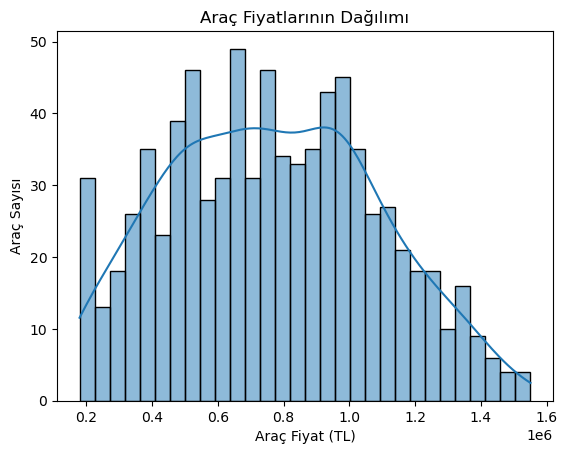

In [13]:
sns.histplot(
    df["fiyat_tl"],
    bins=30,
    kde=True
)
plt.title("Araç Fiyatlarının Dağılımı")
plt.xlabel("Araç Fiyat (TL)")
plt.ylabel("Araç Sayısı")
plt.show()

### 

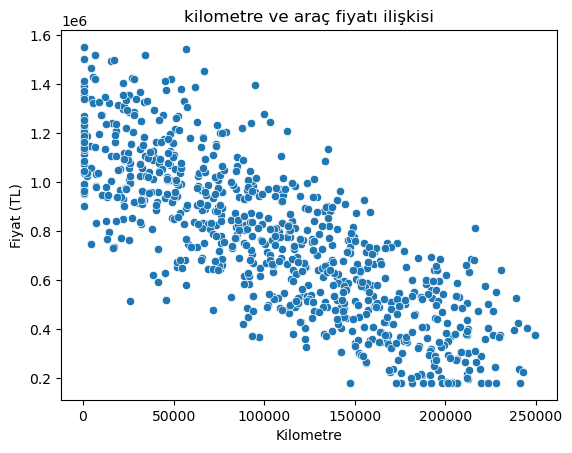

In [15]:
sns.scatterplot(
    data=df,
    x="kilometre",
    y="fiyat_tl"
)
plt.title("kilometre ve araç fiyatı ilişkisi")
plt.xlabel("Kilometre")
plt.ylabel("Fiyat (TL)")
plt.show()

In [16]:
# 2 deger sarasındakı ilişki bu ilişkini -1 0 +1 -> Gücünü ve Yönünü

In [17]:
df

,marka,model_yili,kilometre,motor_hacmi_cc,yakit_turu,vites,beygir_gucu,hasar_kaydi_adedi,bakim_gecmisi,kasa_tipi,fiyat_tl
0,Hyundai,2023,27775.0,1800,Elektrik,Otomatik,125.0,0.0,Yok,Hatchback,1205187.0
1,Renault,2011,164400.0,1400,Benzin,Otomatik,96.0,2.0,Yok,SUV,346060.0
2,Toyota,2019,93560.0,1800,Elektrik,Otomatik,139.0,0.0,Yok,Hatchback,984269.0
3,Ford,2012,155095.0,2000,Dizel,Manuel,153.0,1.0,Yok,Hatchback,408760.0
4,Fiat,2018,129024.0,1800,Elektrik,Manuel,NaN,0.0,Yok,Hatchback,939370.0
...,...,...,...,...,...,...,...,...,...,...,...
795,Hyundai,2022,46175.0,1800,Dizel,Otomatik,126.0,0.0,Tam,Station Wagon,1013429.0
796,Volkswagen,2013,136309.0,1200,LPG,Otomatik,91.0,0.0,Kısmi,Sedan,641191.0
797,Ford,2012,126707.0,1200,Hibrit,Manuel,106.0,0.0,Yok,SUV,509171.0
798,Ford,2023,72745.0,1000,Hibrit,Manuel,NaN,1.0,Tam,Station Wagon,950085.0


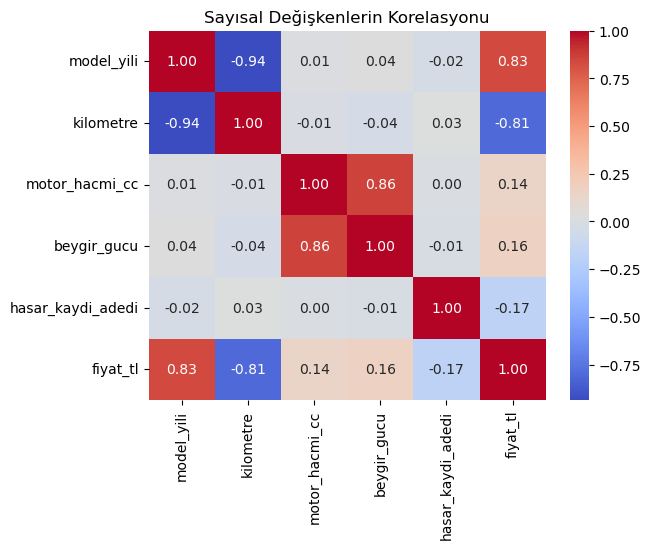

In [19]:
numeric_df = df.select_dtypes(include="number")

corre = numeric_df.corr()

sns.heatmap(
    corre,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Sayısal Değişkenlerin Korelasyonu")
plt.show()

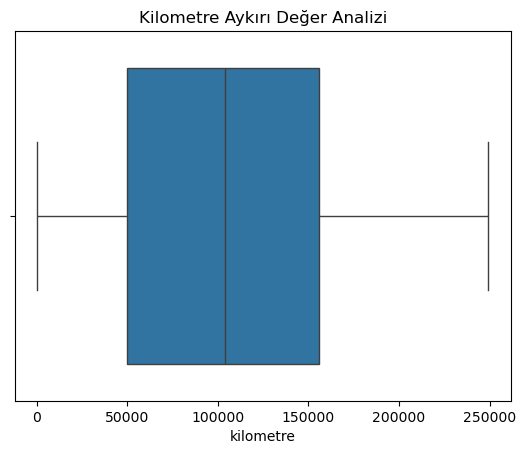

In [21]:
sns.boxplot(x=df["kilometre"])
plt.title("Kilometre Aykırı Değer Analizi")
plt.show()

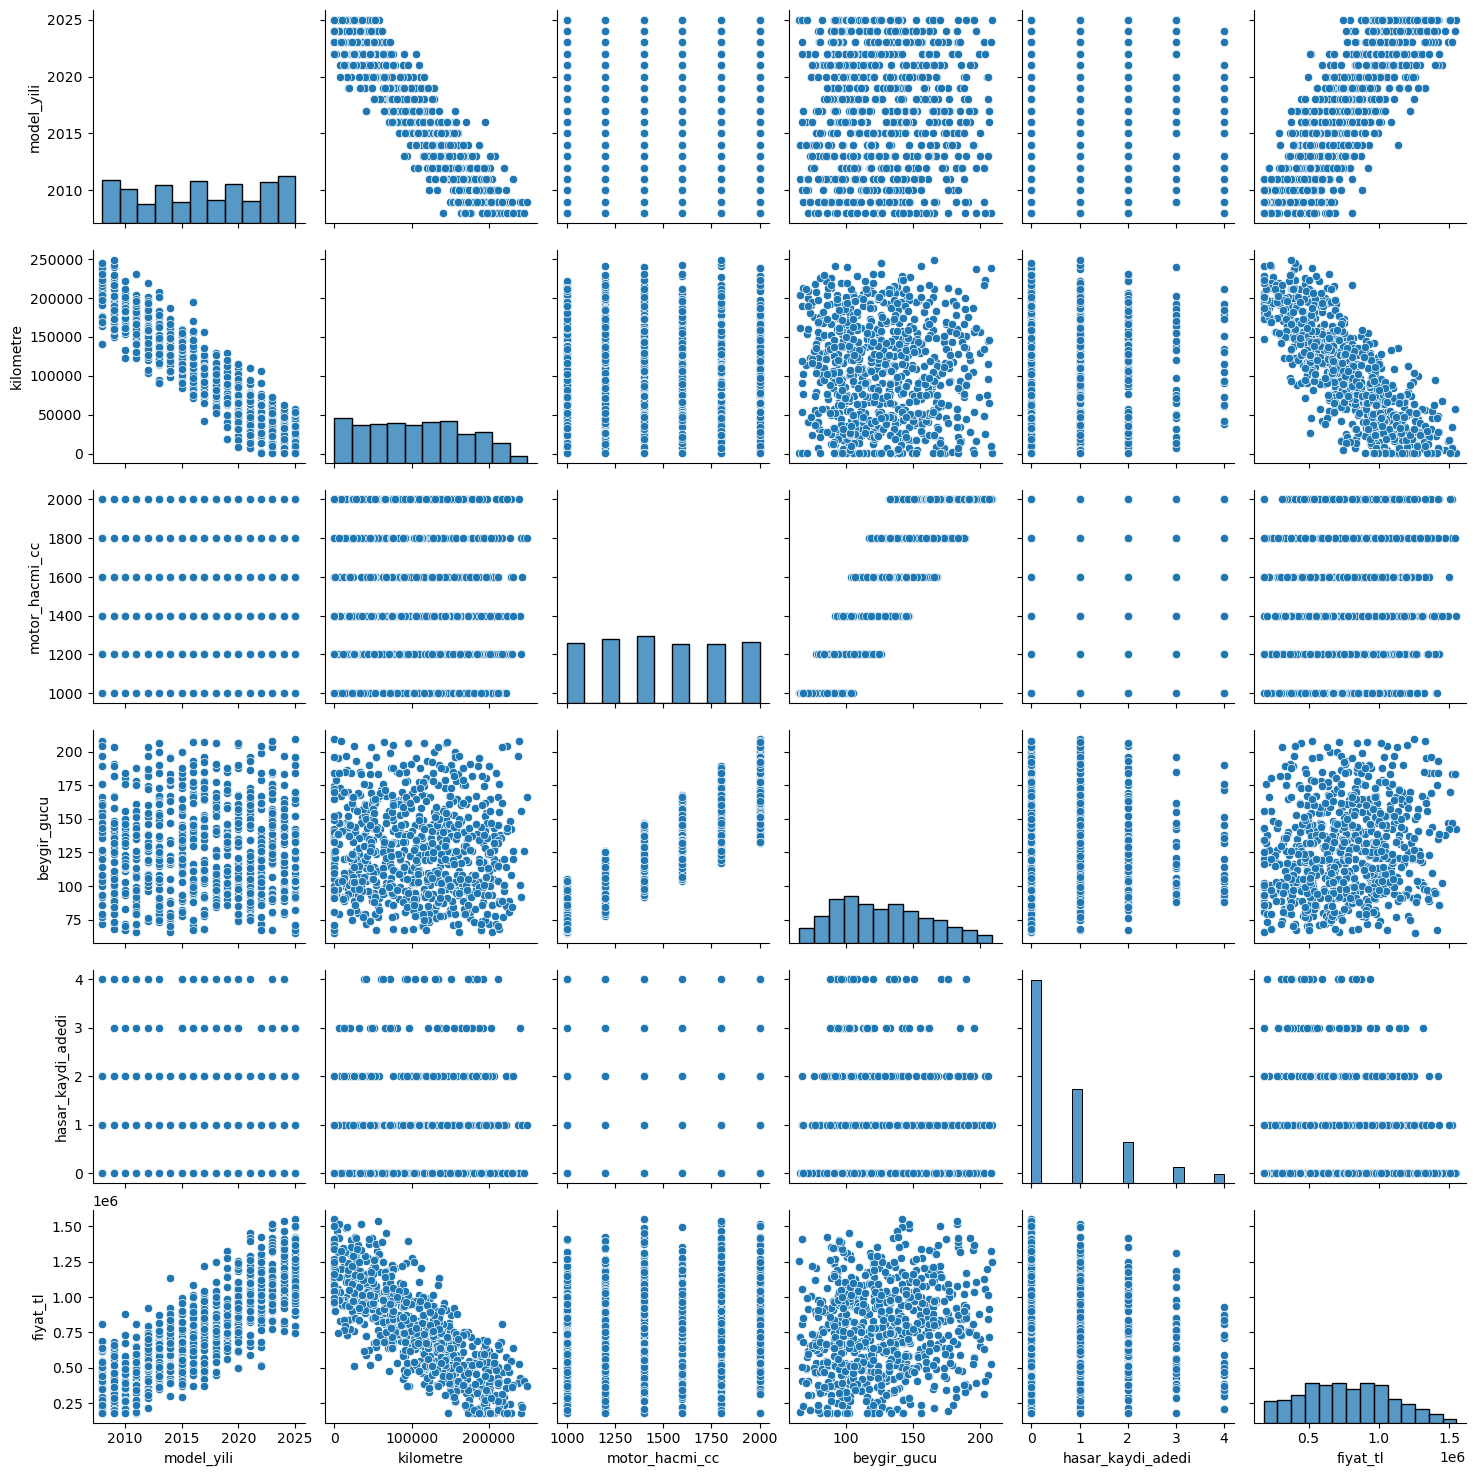

In [22]:
sns.pairplot(df)

In [24]:
Q1 = df["kilometre"].quantile(0.25)
Q3 = df["kilometre"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["kilometre"] < lower_limit) |
    (df["kilometre"] > upper_limit)
]
print("Alt Sınır:",lower_limit)
print("Üst Sınır:",upper_limit)
print("Aykırı Değer Adayı Sayısı:",len(outliers))

Alt Sınır: -108763.125
Üst Sınır: 314565.875
Aykırı Değer Adayı Sayısı: 0


In [25]:
X = df.drop("fiyat_tl",axis=1)
y=df["fiyat_tl"]

print("X Boy:",X.shape)
print("Y boy:",y.shape)

X Boy: (800, 10)
Y boy: (800,)


In [27]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42)

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [31]:
simple_model = LinearRegression()
simple_model.fit(
    X_train[["kilometre"]],
    y_train
)
simple_predictions = simple_model.predict(
    X_test[["kilometre"]]
)
simple_mae = mean_absolute_error(y_test,simple_predictions)
smiple_r2 = r2_score(y_test,simple_predictions)

print("MAE",simple_mae)
print("R2",smiple_r2)

MAE 159488.9223214285
R2 0.6206766215418531


# simpleimputer , onehotencoder 0-1,
toyota,reanult,fiat ilişki kuramıyor
onehotencoder 0,1,2
columntransformer 

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

In [33]:
df.columns

Index(['marka', 'model_yili', 'kilometre', 'motor_hacmi_cc', 'yakit_turu',
       'vites', 'beygir_gucu', 'hasar_kaydi_adedi', 'bakim_gecmisi',
       'kasa_tipi', 'fiyat_tl'],
      dtype='object')

In [34]:
numeric_features = [
    "model_yili",
    "kilometre",
    "motor_hacmi_cc",
    "beygir_gucu",
    "hasar_kaydi_adedi"
]
categorical_features = [
    "marka",
    "yakit_turu",
    "vites",
    "bakim_gecmisi",
    "kasa_tipi"
]



numeric_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train,y_train)

predictions = model.predict(X_test)


In [35]:
predictions

array([ 638069.86663708,  499083.85325721,  345106.94500081,
        459335.58691767,  278914.28384759,  157414.99454705,
        774100.95066193,  462815.53830162,  870651.65554932,
        322738.48723742,  421446.99750565,  688750.79269062,
        795571.08500384, 1261443.80051203, 1031707.9311949 ,
        366725.80136326, 1112974.69015384,  451458.50021982,
        268065.47972877,  434082.6224369 ,  293630.7884046 ,
       1118121.30447669, 1343372.02649939,  991182.80254099,
        769962.41095051,  548206.80208927,  345841.09066603,
       1050600.95854279,  873600.20287088,  952466.0658858 ,
        271796.36223817,  557549.84890339,  792622.03206591,
        968987.4613464 ,  694666.41954631, 1057133.66559777,
        427623.85020109,  663124.63323909,  532527.55225876,
       1205065.44034179,  389063.71179447, 1170036.47130024,
        514256.00212888,  653173.14766309,  885637.15826532,
        567693.74484073,  423089.18890864,  989245.19134948,
       1162137.78008166,

In [36]:
comparision = pd.DataFrame({
    "Gercek_Fiyat":y_test.values,
    "Tahmin_Fiyat":predictions
})
comparision["Hata"] = (
    comparision["Gercek_Fiyat"] - comparision["Tahmin_Fiyat"]
)

comparision.head(10)

,Gercek_Fiyat,Tahmin_Fiyat,Hata
0,667784.0,638069.866637,29714.133363
1,439715.0,499083.853257,-59368.853257
2,343999.0,345106.945001,-1107.945001
3,338119.0,459335.586918,-121216.586918
4,293064.0,278914.283848,14149.716152
5,231314.0,157414.994547,73899.005453
6,653760.0,774100.950662,-120340.950662
7,661015.0,462815.538302,198199.461698
8,852502.0,870651.655549,-18149.655549
9,357486.0,322738.487237,34747.512763


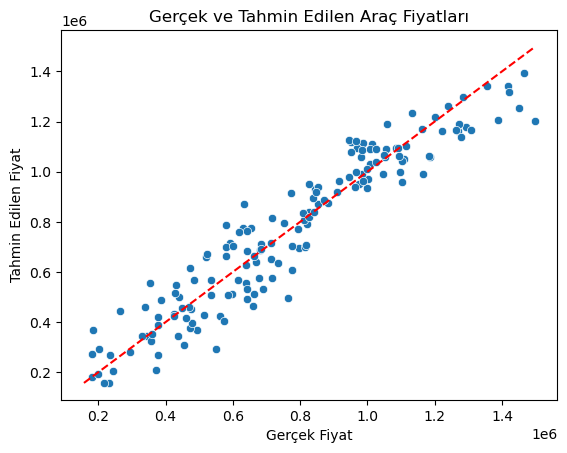

In [39]:
sns.scatterplot(
    x=y_test,
    y=predictions
)

min_value = min(y_test.min(),predictions.min())
max_value = max(y_test.max(),predictions.max())

plt.plot(
    [min_value,max_value],
    [min_value,max_value],
    linestyle="--",
    color="r"
)

plt.xlabel("Gerçek Fiyat")
plt.ylabel("Tahmin Edilen Fiyat")
plt.title("Gerçek ve Tahmin Edilen Araç Fiyatları")
plt.show()

In [40]:
residuals = y_test - predictions
print(residuals.head())

696     29714.133363
667    -59368.853257
63      -1107.945001
533   -121216.586918
66      14149.716152
Name: fiyat_tl, dtype: float64


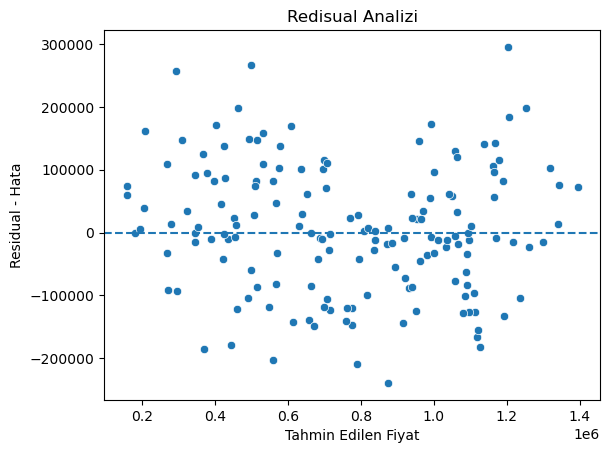

In [42]:
sns.scatterplot(
    x=predictions,
    y=residuals
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Tahmin Edilen Fiyat")
plt.ylabel("Residual - Hata")
plt.title("Redisual Analizi")
plt.show()

In [43]:
df.columns

Index(['marka', 'model_yili', 'kilometre', 'motor_hacmi_cc', 'yakit_turu',
       'vites', 'beygir_gucu', 'hasar_kaydi_adedi', 'bakim_gecmisi',
       'kasa_tipi', 'fiyat_tl'],
      dtype='object')

In [49]:
yeni_arac = pd.DataFrame([{
    "marka":"Toyota",
    "model_yili":2021,
    "kilometre":65000,
    "motor_hacmi_cc":1600,
    "yakit_turu":"Benzin",
    "vites":"Otomatik",
    "beygir_gucu":125,
    "hasar_kaydi_adedi":0,
    "bakim_gecmisi":"Tam",
    "kasa_tipi":"Sedan"
}])

tahmin_fiyat = model.predict(yeni_arac)
print("Tahmin araç fiyatı:",round(tahmin_fiyat[0],2),"TL")

Tahmin araç fiyatı: 1043887.96 TL
